[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_stablecoin_conc/BA_L1_stablecoin_conc.ipynb)

# BA_L1_stablecoin_conc: Stablecoin Issuers

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Shares of Tether (USDT) and USD Coin (USDC) in the circulating supply of all USD stablecoins and the Herfindahl-Hirschman index (HHI) of stablecoin issuers, daily, January 2019 to 18 September 2026, from a DefiLlama snapshot.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

DefiLlama reports the circulating supply, in USD, of every USD stablecoin; the snapshot holds the total (`all`) and
one series per coin (`id_<n>`: Tether is id 1, USD Coin id 2). The sample runs from 1 January 2019 to
18 September 2026. The share of issuer $i$ on day $t$ is $w_{i,t} = Q_{i,t} / \sum_j Q_{j,t}$, its supply over the
total, and the **Herfindahl–Hirschman index** (HHI) is

$$\mathrm{HHI}_t = \sum_i w_{i,t}^2,$$

from $1/N$ (equal shares among $N$ issuers) to 1 (one issuer). $1/\mathrm{HHI}$ is the effective number of issuers.

**How to read the chart.** Left: the shares of Tether and USD Coin and their sum. Right: the HHI of all issuers.
Concentration falls when new stablecoins grow faster than the two largest, and rises when one of them loses ground.

In [5]:
import gzip, json, urllib.request

SNAP_END = '2026-09-18'
src = data_file('snapshots', 'stablecoin16-20261021-979c073f25783889.json.gz')
raw = urllib.request.urlopen(src).read() if src.startswith('http') else open(src, 'rb').read()
P = json.loads(gzip.decompress(raw))['payloads']


def stable_series(key):
    # circulating supply in USD of one DefiLlama payload ('all' or 'id_<n>'), daily
    s = pd.Series({pd.to_datetime(int(x['date']), unit='s'): (x.get('totalCirculatingUSD') or {}).get('peggedUSD', np.nan)
                   for x in P[key]})
    return s.sort_index().loc[:SNAP_END]


tot = stable_series('all')
ids = [k for k in P if k.startswith('id_')]
panel = pd.DataFrame({k: stable_series(k) for k in ids}).reindex(tot.index).loc['2019-01-01':]
tot19 = tot.loc['2019-01-01':]
sh = panel.div(tot19, axis=0)
hhi_s = (sh.fillna(0) ** 2).sum(axis=1)
print(f'{len(ids)} stablecoins; {len(sh):,} days, {sh.index[0]:%d %B %Y} to {sh.index[-1]:%d %B %Y}')

47 stablecoins; 2,818 days, 01 January 2019 to 18 September 2026


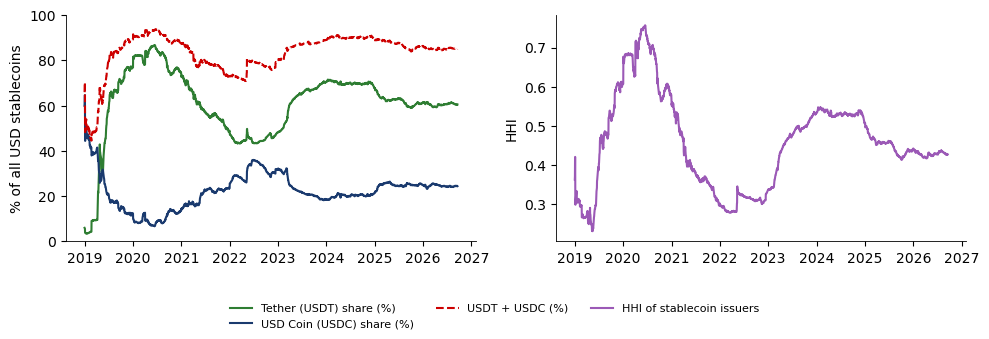

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(sh.index, 100 * sh['id_1'], color=GREEN, label='Tether (USDT) share (%)')
ax[0].plot(sh.index, 100 * sh['id_2'], color=BLUE, label='USD Coin (USDC) share (%)')
ax[0].plot(sh.index, 100 * (sh['id_1'] + sh['id_2']), color=RED, ls='--', label='USDT + USDC (%)')
ax[0].set_ylabel('% of all USD stablecoins'); ax[0].set_ylim(0, 100)
ax[1].plot(hhi_s.index, hhi_s, color=ETH, label='HHI of stablecoin issuers')
ax[1].set_ylabel('HHI')
slide_legend(fig, 0.16)
save_fig(fig, 'ba_l1_stablecoin_conc')

The numbers quoted on the slide: shares and HHI on four dates (the nearest day in the data).

In [7]:
rows = []
for d in ['2020-01-01', '2022-04-01', '2023-08-19', '2026-09-18']:
    i = sh.index.get_indexer([pd.Timestamp(d)], method='nearest')[0]
    rows.append({'date': sh.index[i].date(), 'Tether share (%)': 100 * sh['id_1'].iloc[i],
                 'USD Coin share (%)': 100 * sh['id_2'].iloc[i], 'HHI of issuers': hhi_s.iloc[i],
                 'total supply (USD bn)': tot19.iloc[i] / 1e9})
print(pd.DataFrame(rows).set_index('date').round(3).to_string())

            Tether share (%)  USD Coin share (%)  HHI of issuers  total supply (USD bn)
date                                                                                   
2020-01-01            76.783              12.426           0.607                  4.171
2022-04-01            43.999              27.917           0.282                186.622
2023-08-19            67.497              20.734           0.500                122.655
2026-09-18            60.508              24.396           0.427                302.982
